In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Defining goal profile

[0.93548928 0.94754981 0.95841848 0.9680697  0.9764807  0.98363164
 0.98950562 0.99408875 0.99737018 0.99934216 1.         0.99934216
 0.99737018 0.99408875 0.98950562 0.98363164 0.9764807  0.9680697
 0.95841848 0.94754981]


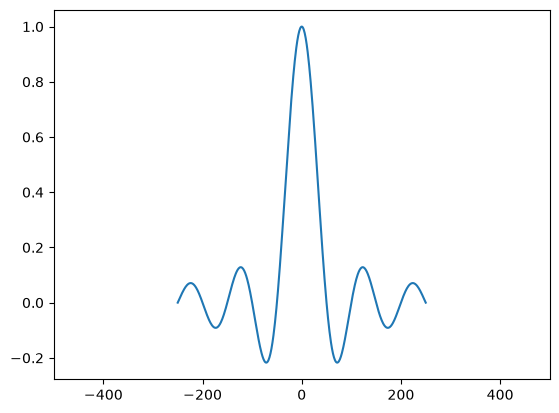

C:\Users\PC\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\PC\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


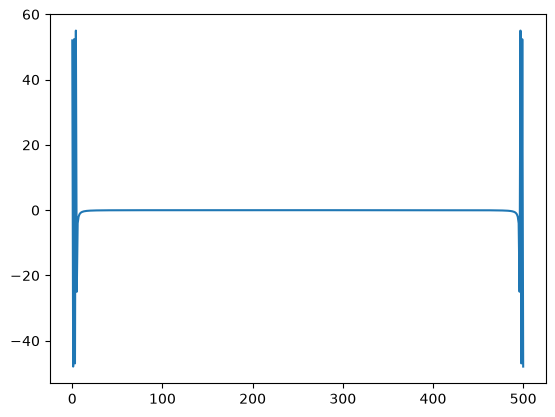

In [ ]:
# https://www.opticsforhire.com/blog/an-overview-about-pi-shapers/

# For a transmissive DOE, the corresponding surface relief (for a refractive material in air) is approximately:

# $$ h(r) = \lambda \phi(r) / (2 \np.pi * (n-1)) $$

# All distance units are pixels (a.u.)
N = 500
xs = np.linspace(-N/2, N/2, N+1)

w = 2e-2
lim = N
profile = np.sinc(xs * w)

plt.plot(xs, profile)
plt.xlim(-lim, lim)
print(profile[240:260])
plt.show()

transform = np.fft.fft(profile)
plt.plot(transform)

## Gerchberg-Saxton algorithm

In [21]:
#pip install pyhank

def KtoR(k, waveLength, focalLength):
    return waveLength * focalLength * k / (2 * np.pi)

def RtoK(r, waveLength, focalLength):
    return 2 * np.pi * r / (waveLength * focalLength)


f = 300 # GHz
v = 3e8
wl = v/f
fl = 0.15 # m
radius = 5e-3 # m
k = RtoK(radius, wl, fl)
print(k)

2.0943951023931955e-07


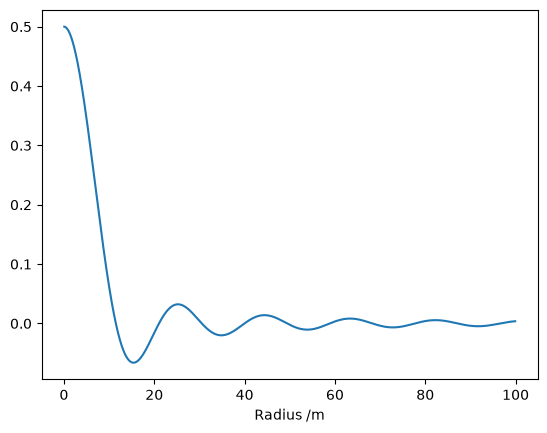

Text(0.5, 0, 'Radial wavevector /m$^{-1}$')

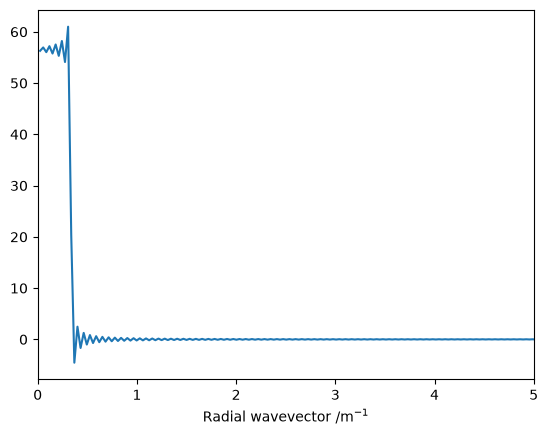

In [23]:
# https://pyhank.readthedocs.io/en/latest/auto_examples/simple_example.html

import numpy as np
from scipy.interpolate import interp1d
#from scipy.fft import fht
import scipy.special
from pyhank import HankelTransform

transformer = HankelTransform(order=0, max_radius=100, n_points=1024)
a = 1/3
f = scipy.special.jv(1, transformer.r * a) / (transformer.r * a)

plt.figure()
plt.plot(transformer.r, f)
plt.xlabel("Radius /m")
plt.show()

ht = transformer.qdht(f)

plt.figure()
plt.plot(transformer.kr, ht)
plt.xlim((0, 5))
plt.xlabel("Radial wavevector /m$^{-1}$")

In [32]:
N = 30

rho = np.linspace(0, 30, N+1)/30

I_target = np.zeros_like(rho)

R = 0.5  # Desired flat-top radius

I_target[rho <= R] = 1.0

print(I_target)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
def MSE_w(aaa):
    return error

def GerchbergSaxton(inputProfile, imageProfile, maxiter = 10000, errMin = 1e-4):

    # define transformer & scale
    N = len(imageProfile)
    transformer = HankelTransform(order=0, max_radius=100, n_points=N)
    r = transformer.r
    kr = transformer.kr
    #a = 1/3
    #f = scipy.special.jv(1, transformer.r * a) / (transformer.r * a)
    # define initial DOE
    U_DOE = np.ones(N, dtype=complex)

    for i in range(maxiter):

        # --- DOE PLANE

        # apply DOE phase
        U_tot = inputProfile * U_DOE

        # propagate to focal plane
        U_image = transformer.qdht(U_tot)

        # ---- IMAGE PLANE

        # Find new intensity
        I_found = np.abs(U_image)**2

        # check for MSE with radial weighting
        error = MSE_w(imageProfile, np.abs(U_image))

        # replace amplitude, retain phase
        U_image = imageProfile * np.exp(1j * np.angle(U_image))

        # Check for flatness
        #flatness = (max(I) - min(I))/(max(I) + min(I))

        if error < errMin:
            break

        # go back to DOE
        U_DOE = transformer.iqdht(U_image)
        U_DOE = np.exp(1j * np.angle(U_DOE))

    return U_DOE

(0.0, 5.0)

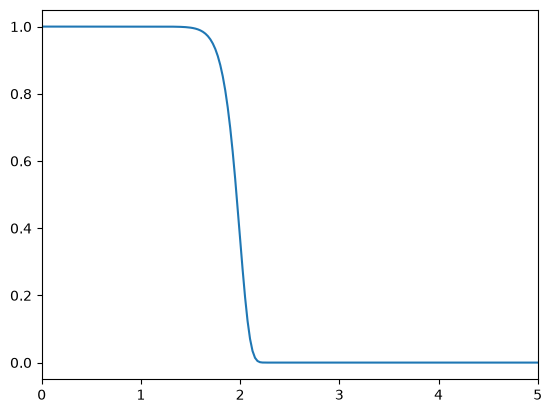

In [47]:
N = 200

xs = np.linspace(0, 200, N+1)/200*5
sigma = 2
p = 10

func = np.exp(-(xs/sigma)**(2*p))
plt.plot(xs, func)
plt.xlim(0, max(xs))

In [ ]:
# Initial Gaussian field
U = A_input.astype(complex)

for iteration in range(1000):

    # Forward propagation
    U_out = transformer.qdht(U)

    # Enforce desired output amplitude
    U_out = np.sqrt(I_target) * np.exp(
        1j * np.angle(U_out)
    )

    # Backward propagation
    U_back = transformer.iqdht(U_out)

    # Enforce original Gaussian input amplitude
    U = A_input * np.exp(
        1j * np.angle(U_back)
    )

In [ ]:
P_in = 2 * np.pi * np.trapezoid(
    np.abs(U_input)**2 * r, r
)

P_doe = 2 * np.pi * np.trapezoid(
    np.abs(U_doe)**2 * r, r
)

print("Input power:", P_in)
print("DOE power:", P_doe)
print("Relative power difference:", abs(P_in-P_doe)/P_in)